# Feature engineering 

Event-locked temporal features.
To capture neural response dynamics beyond noisy instantaneous time bins, we introduced event-locked temporal features summarizing activity around task events. Specifically, we computed the area under the curve (AUC) in temporal windows surrounding each event, as well as difference and ratio features comparing responses across events. These features integrate activity over time, reduce noise, and encode biologically meaningful changes in neural engagement that are not captured by single time-point values.

/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_77409/1203680987.py:70: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[c2] = auc_e2
/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_77409/1203680987.py:71: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[c3] = auc_e2 - auc_e1
/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_77409/1203680987.py:72: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consi

Added 184 new feature columns (AUC e1/e2 + diff + ratio).
Example bases: [np.str_('wS1_L1_INH'), np.str_('wM2_L6a_EXC'), np.str_('wS1_L4_EXC')]
Example trial indices: [2947, 2174, 2185]


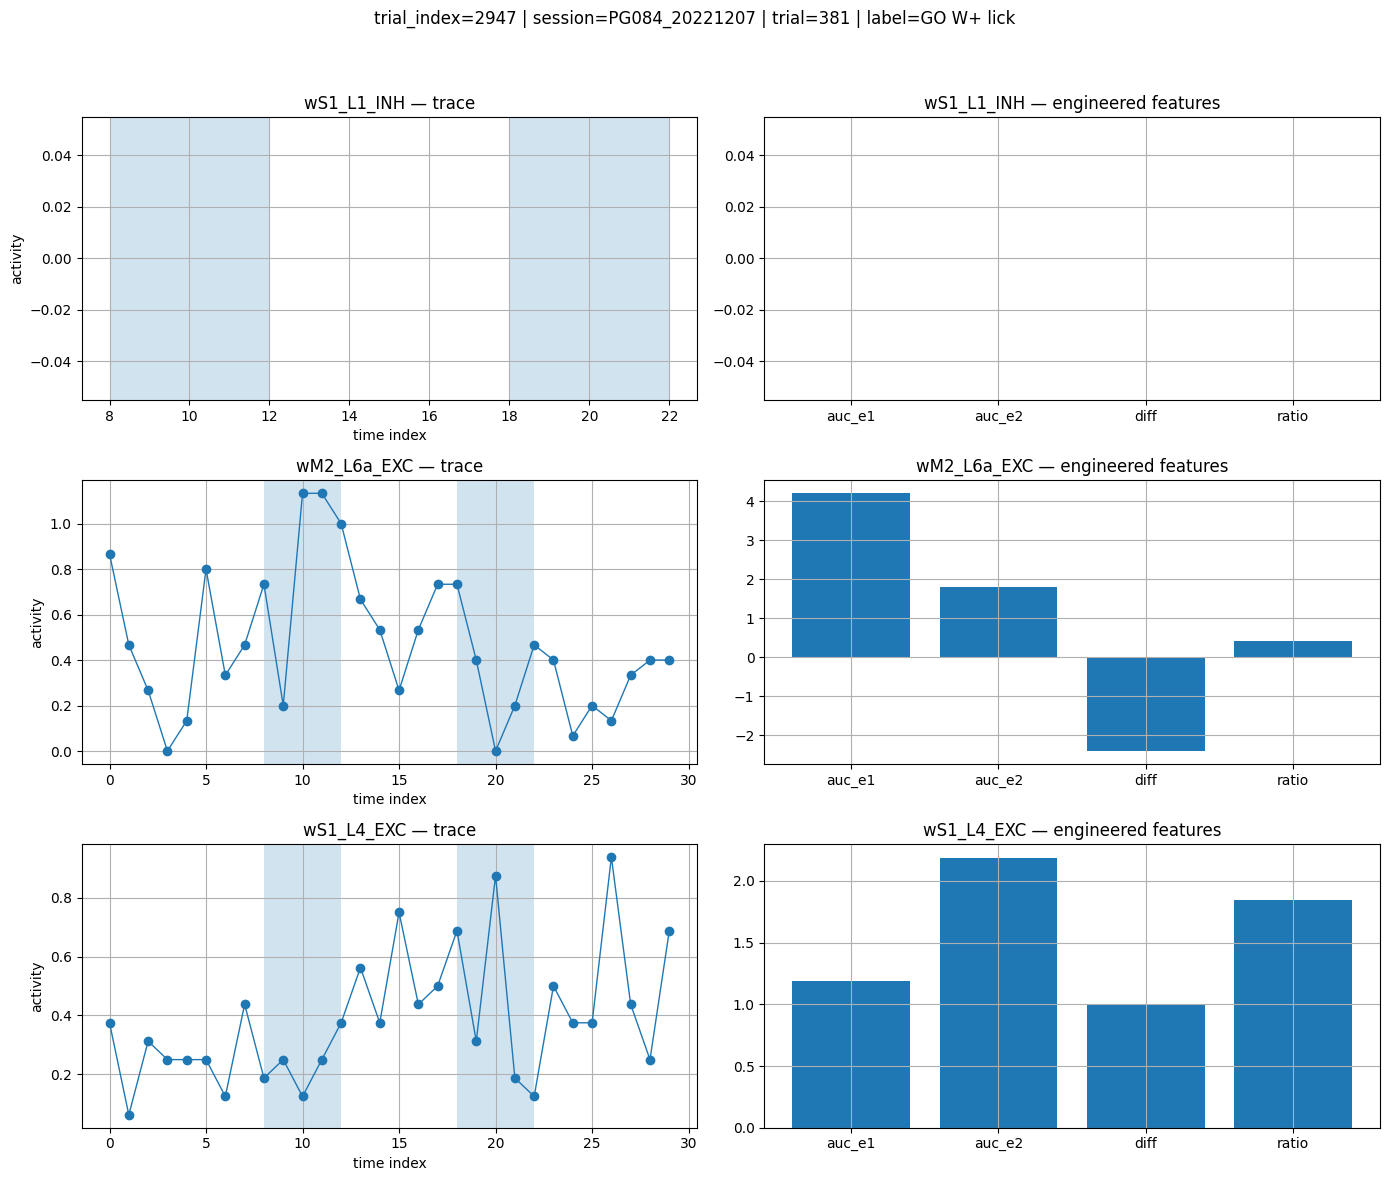

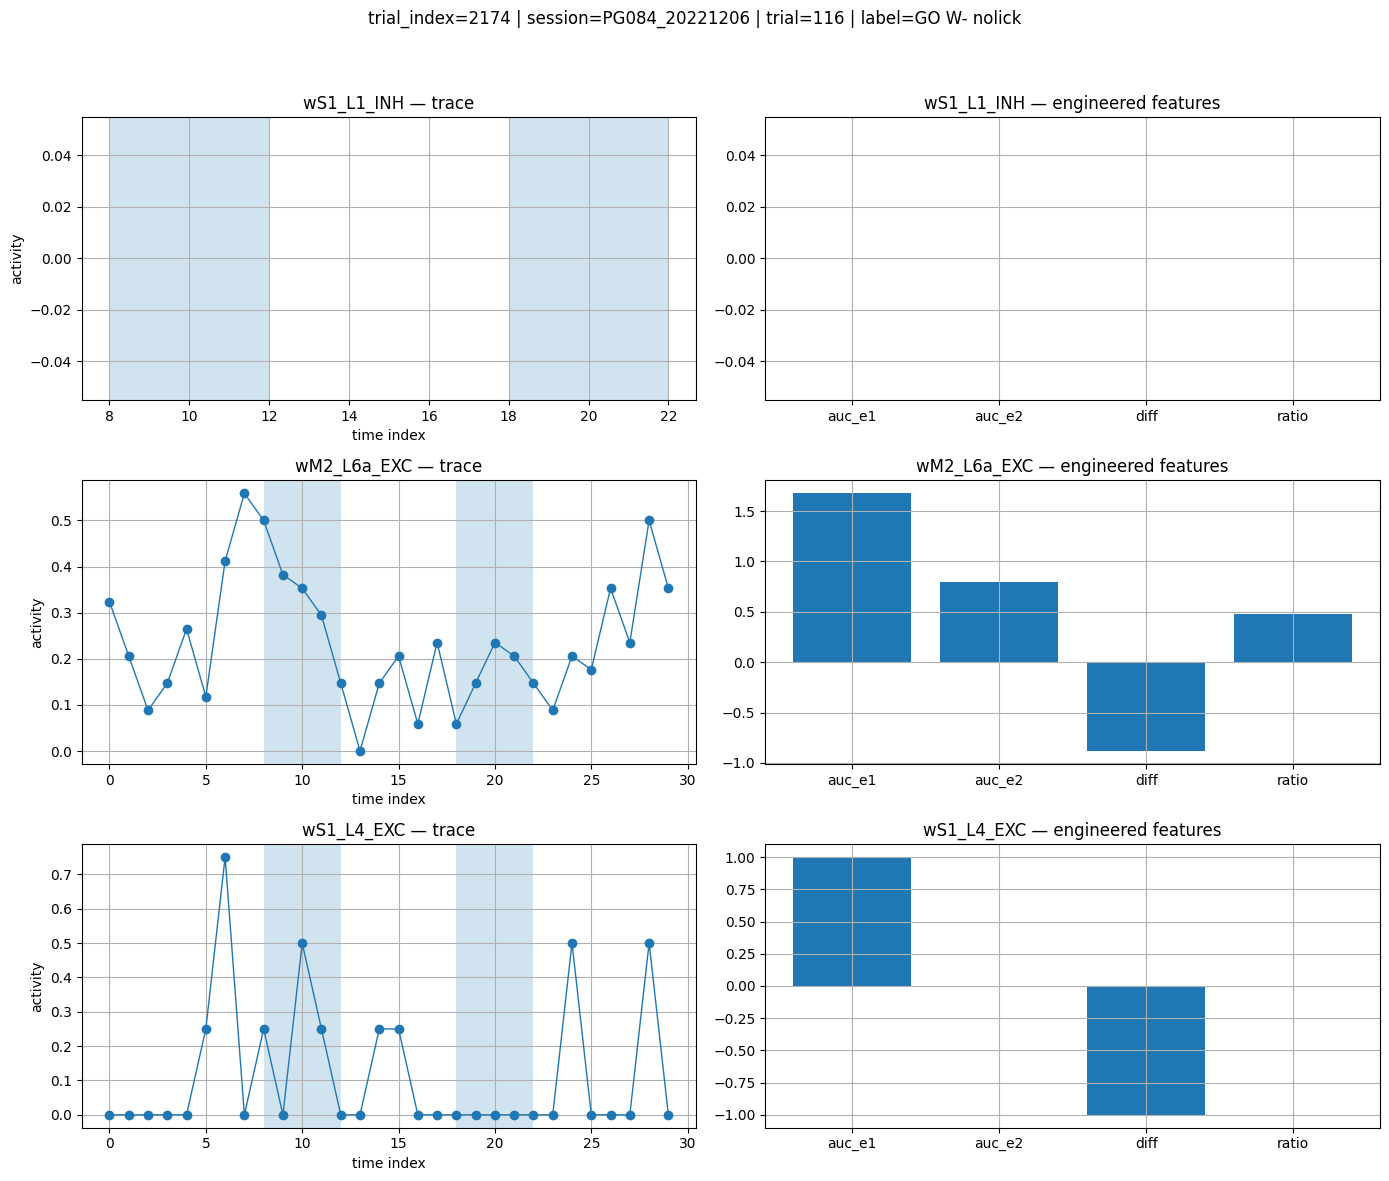

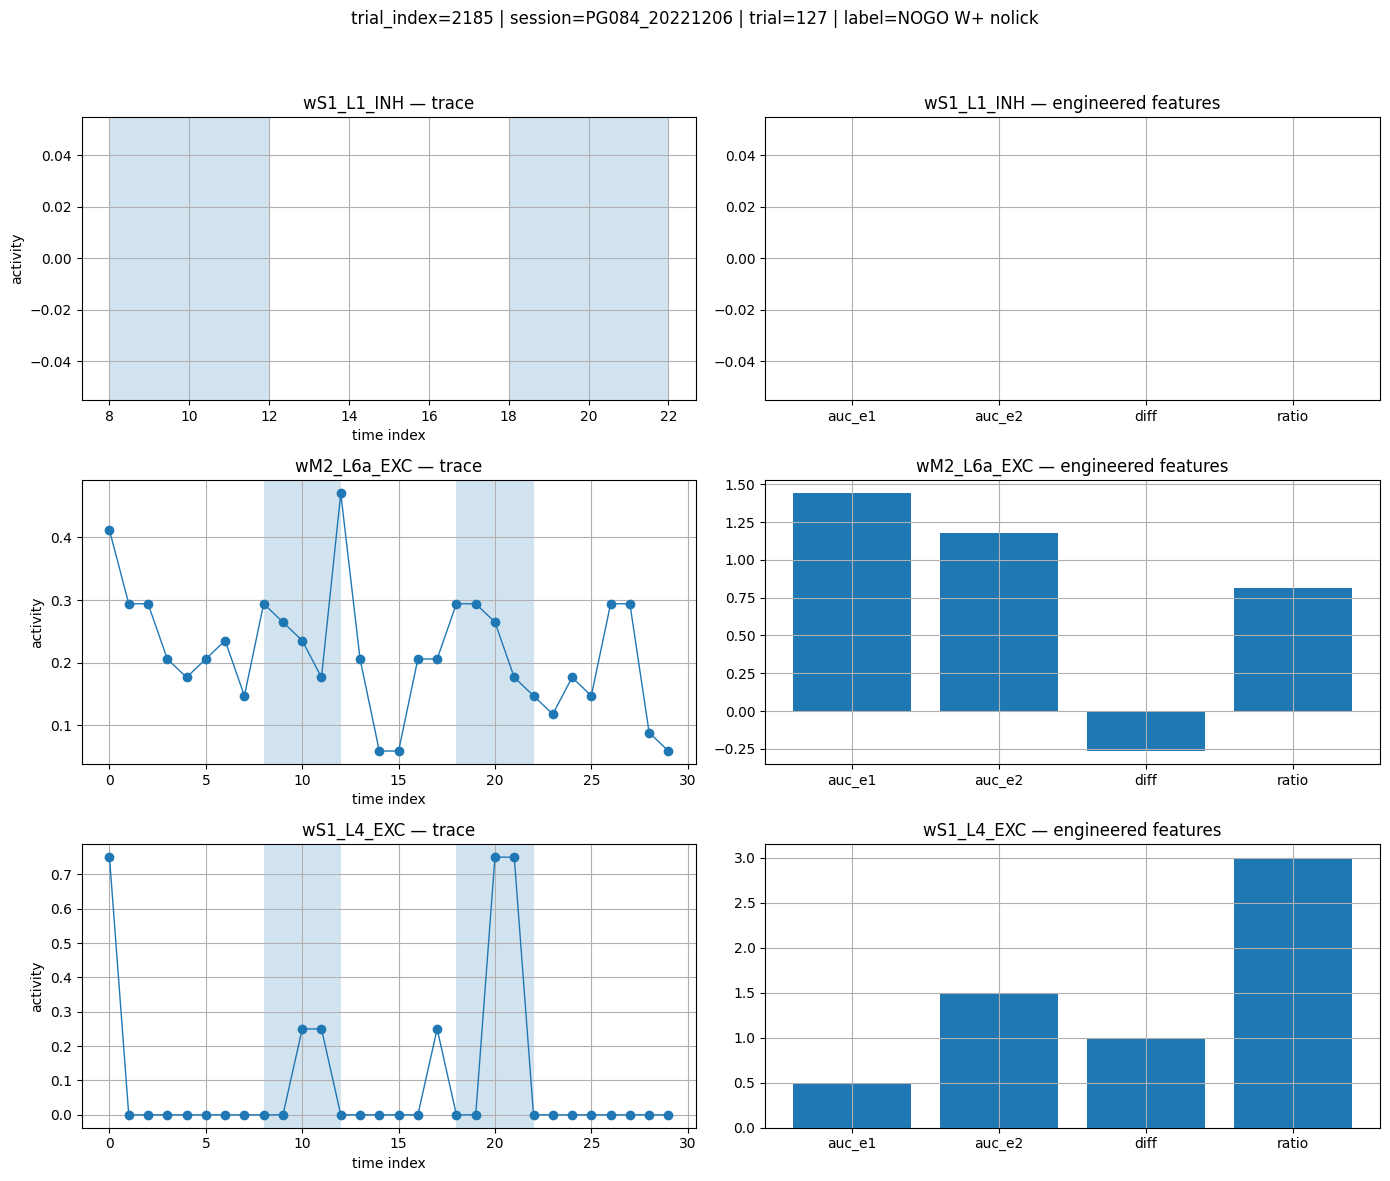

In [4]:
# Single self-contained cell:
# 1) loads train.csv
# 2) creates event-locked AUC features (auc_e1, auc_e2, diff, ratio) for ALL traces
# 3) plots them on a few example trials + a few example traces

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =============================
# Settings (adjust if needed)
# =============================
PATH = "data/raw/train.csv"
E1 = range(8, 13)      # event1 window (8..12)
E2 = range(18, 23)     # event2 window (18..22)
N_TRIALS_TO_SHOW = 3   # number of example trials to plot
N_TRACES_TO_SHOW = 3   # number of example traces (bases) to plot
EPS = 1e-8

# =============================
# Load
# =============================
df = pd.read_csv(PATH)

# =============================
# Find time-binned columns: "<base>_time_<k>"
# =============================
pat = re.compile(r"^(.*)_time_(\d+)$")
time_cols = []
for c in df.columns:
    m = pat.match(c)
    if m:
        base = m.group(1)
        t = int(m.group(2))
        time_cols.append((c, base, t))

if len(time_cols) == 0:
    raise ValueError("No columns match pattern '<base>_time_<k>'. Check your CSV column names.")

# Group by base
by_base = {}
for c, base, t in time_cols:
    by_base.setdefault(base, []).append((t, c))

# =============================
# Create new AUC features for ALL bases
# =============================
new_cols = []
for base, tc in by_base.items():
    t_to_col = {t: col for t, col in tc}

    cols_e1 = [t_to_col[t] for t in E1 if t in t_to_col]
    cols_e2 = [t_to_col[t] for t in E2 if t in t_to_col]
    if len(cols_e1) == 0 or len(cols_e2) == 0:
        continue

    X1 = df[cols_e1].to_numpy()
    X2 = df[cols_e2].to_numpy()

    auc_e1 = np.nansum(X1, axis=1)
    auc_e2 = np.nansum(X2, axis=1)

    c1 = f"{base}_auc_e1"
    c2 = f"{base}_auc_e2"
    c3 = f"{base}_auc_diff"
    c4 = f"{base}_auc_ratio"

    df[c1] = auc_e1
    df[c2] = auc_e2
    df[c3] = auc_e2 - auc_e1
    df[c4] = auc_e2 / (auc_e1 + EPS)

    new_cols.extend([c1, c2, c3, c4])

print(f"Added {len(set(new_cols))} new feature columns (AUC e1/e2 + diff + ratio).")

# =============================
# Pick some example bases + trials for plotting
# =============================
bases = sorted(by_base.keys())
np.random.seed(0)

# Keep bases that actually got features (i.e., have auc columns)
valid_bases = []
for b in bases:
    if f"{b}_auc_e1" in df.columns and f"{b}_auc_e2" in df.columns:
        valid_bases.append(b)

if len(valid_bases) == 0:
    raise ValueError("No bases had both E1 and E2 windows available. Adjust E1/E2 ranges.")

bases_show = list(np.random.choice(valid_bases, size=min(N_TRACES_TO_SHOW, len(valid_bases)), replace=False))

# choose trials with non-null label if exists
label_col = "TRIAL_TYPE" if "TRIAL_TYPE" in df.columns else None
trial_idxs = np.random.choice(df.index.values, size=min(N_TRIALS_TO_SHOW, len(df)), replace=False)

print("Example bases:", bases_show)
print("Example trial indices:", trial_idxs.tolist())

# =============================
# Helper: get a time-series vector for one base and one row
# =============================
def get_trace(df_row, base, by_base_dict):
    tc = sorted(by_base_dict[base], key=lambda x: x[0])  # list of (t, col)
    t_vals = [t for t, _ in tc]
    x_vals = np.array([df_row[col] for _, col in tc], dtype=float)
    return np.array(t_vals), x_vals

# =============================
# Plot: for each chosen trial, show a few traces and their computed AUC features
# =============================
for ridx in trial_idxs:
    row = df.loc[ridx]
    title = f"trial_index={ridx}"
    if "session_id" in df.columns:
        title += f" | session={row['session_id']}"
    if "trial_number" in df.columns:
        title += f" | trial={row['trial_number']}"
    if label_col:
        title += f" | label={row[label_col]}"

    fig = plt.figure(figsize=(14, 4 * len(bases_show)))
    fig.suptitle(title)

    for i, base in enumerate(bases_show, start=1):
        t, x = get_trace(row, base, by_base)

        # AUC values for this trial
        auc_e1 = row.get(f"{base}_auc_e1", np.nan)
        auc_e2 = row.get(f"{base}_auc_e2", np.nan)
        auc_diff = row.get(f"{base}_auc_diff", np.nan)
        auc_ratio = row.get(f"{base}_auc_ratio", np.nan)

        # ---- Left: trace with event windows shaded ----
        ax1 = plt.subplot(len(bases_show), 2, 2*i - 1)
        ax1.plot(t, x, marker="o", linewidth=1)
        ax1.axvspan(min(E1), max(E1), alpha=0.2)
        ax1.axvspan(min(E2), max(E2), alpha=0.2)
        ax1.set_title(f"{base} — trace")
        ax1.set_xlabel("time index")
        ax1.set_ylabel("activity")
        ax1.grid(True)

        # ---- Right: barplot of features for this base on this trial ----
        ax2 = plt.subplot(len(bases_show), 2, 2*i)
        vals = [auc_e1, auc_e2, auc_diff, auc_ratio]
        names = ["auc_e1", "auc_e2", "diff", "ratio"]
        ax2.bar(names, vals)
        ax2.set_title(f"{base} — engineered features")
        ax2.grid(True)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# PARAMS
# =========================
TRAIN_PATH = "data/raw/train.csv"
OUT_DIR = "plots_per_session"
MAX_SESSIONS = 20          # limite pour pas générer 500 images
MAX_SIGNALS = 12           # nb de panneaux par figure
DPI = 160

os.makedirs(OUT_DIR, exist_ok=True)

# =========================
# LOAD
# =========================
df = pd.read_csv(TRAIN_PATH)

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# garder seulement les features temporelles (ex: A1_L1_EXC_time_0)
time_cols = [c for c in df.columns if "_time_" in c]

# forcer en numérique (corrige ton erreur dtype object)
df[time_cols] = df[time_cols].apply(pd.to_numeric, errors="coerce")

# =========================
# NORMALISATION PAR SESSION
# =========================
df[time_cols] = df.groupby("session_id")[time_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# =========================
# PARSER COLONNES -> signal + time
# =========================
# A1_L1_EXC_time_12 -> signal="A1_L1_EXC", time=12
col_to_signal = {c: c.rsplit("_time_", 1)[0] for c in time_cols}
col_to_time   = {c: int(c.rsplit("_time_", 1)[1]) for c in time_cols}
signals = sorted(set(col_to_signal.values()))

# =========================
# PLOT PAR SESSION
# =========================
sessions = df["session_id"].unique()[:MAX_SESSIONS]

for sid in sessions:
    d = df[df["session_id"] == sid]

    # choisir quelques signaux (sinon trop de panneaux)
    sigs = signals[:MAX_SIGNALS]

    n = len(sigs)
    ncols = 3
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows), squeeze=False)
    axes = axes.ravel()

    for i, sig in enumerate(sigs):
        ax = axes[i]

        # colonnes de ce signal
        cols_sig = [c for c in time_cols if col_to_signal[c] == sig]
        cols_sig = sorted(cols_sig, key=lambda c: col_to_time[c])
        times = np.array([col_to_time[c] for c in cols_sig])

        # une courbe par TRIAL_TYPE (moyenne sur les trials)
        for ttype, dtt in d.groupby("TRIAL_TYPE"):
            y = dtt[cols_sig].mean(axis=0).to_numpy()
            ax.plot(times, y, label=str(ttype))

        ax.set_title(sig)
        ax.set_xlabel("Time bin")
        ax.set_ylabel("Activity (z-score, per session)")
        ax.grid(alpha=0.3)

    # cacher axes inutilisés
    for j in range(n, len(axes)):
        axes[j].axis("off")

    # légende unique
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right")

    fig.suptitle(f"Session {sid} — activité vs temps (normalisée par session)", y=0.995)
    fig.tight_layout()

    out = os.path.join(OUT_DIR, f"session_{sid}.png")
    fig.savefig(out, dpi=DPI)
    plt.close(fig)

print(f"✅ Terminé. Images dans: {OUT_DIR}")


✅ Terminé. Images dans: plots_per_session


Below we just add 4 features, to have the global shape of the code but it's clearly not enough to make a difference vs the raw pipeline without feature engineering. 

In [8]:
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# =============================
# PARAMÈTRES
# =============================
K_TOP = 400
E1 = set(range(8, 13))      # 8..12
E2 = set(range(18, 23))     # 18..22
EPS = 1e-6

# =============================
# 1) Charger + nettoyage + features numériques
# =============================
df = pd.read_csv("data/raw/train.csv")
meta_cols = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop colonnes constantes
constant_cols = [
    c for c in df.columns
    if c not in meta_cols and df[c].nunique(dropna=False) <= 1
]
df = df.drop(columns=constant_cols)

# candidates = toutes sauf meta
cand_cols = [c for c in df.columns if c not in meta_cols]

# forcer numérique
df[cand_cols] = df[cand_cols].apply(pd.to_numeric, errors="coerce")

# garder numériques
feature_cols = [c for c in cand_cols if pd.api.types.is_numeric_dtype(df[c])]

# normalisation par session (comme toi)
df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# y / groups
le = LabelEncoder()
y = le.fit_transform(df["TRIAL_TYPE"].values)
num_classes = len(le.classes_)
groups = df["session_id"].values

print("Classes:", le.classes_)
print("Nb features (avant folds):", len(feature_cols))

# regex time
pat = re.compile(r".*_time_(\d+)$")

# =============================
# 2) Matrice complète
# =============================
X_all = df[feature_cols].to_numpy()
print("X_all shape:", X_all.shape)

# =============================
# 3) LOSO
# =============================
logo = LeaveOneGroupOut()
accs = []

for fold, (tr, te) in enumerate(logo.split(X_all, y, groups), 1):
    test_session = np.unique(groups[te])[0]

    X_train_raw = X_all[tr]
    X_test_raw  = X_all[te]
    y_train = y[tr]
    y_test  = y[te]

    # --- (IMPORTANT) enlever colonnes all-NaN dans le TRAIN de ce fold
    # mask_keep[j] = True si la colonne j a au moins une valeur non-NaN dans le train
    mask_keep = ~np.all(np.isnan(X_train_raw), axis=0)

    # appliquer au train et au test (mêmes colonnes gardées)
    X_train_raw = X_train_raw[:, mask_keep]
    X_test_raw  = X_test_raw[:, mask_keep]

    # feature names correspondants (pour reconstruire e1/e2 sur ce fold)
    feature_cols_fold = [c for c, keep in zip(feature_cols, mask_keep) if keep]

    # indices E1/E2 DANS L'ESPACE DU FOLD
    e1_idx = []
    e2_idx = []
    for j, c in enumerate(feature_cols_fold):
        m = pat.match(c)
        if not m:
            continue
        t = int(m.group(1))
        if t in E1:
            e1_idx.append(j)
        if t in E2:
            e2_idx.append(j)

    e1_idx = np.array(e1_idx, dtype=int)
    e2_idx = np.array(e2_idx, dtype=int)

    if len(e1_idx) == 0 or len(e2_idx) == 0:
        raise ValueError(f"Fold {fold} ({test_session}): E1/E2 ne match aucune colonne après filtrage all-NaN.")

    # A) imputation
    imp = KNNImputer(n_neighbors=2)
    X_train = imp.fit_transform(X_train_raw)
    X_test  = imp.transform(X_test_raw)

    # B) ANOVA top 400 (sur colonnes fold)
    f_scores, _ = f_classif(X_train, y_train)
    top = np.argsort(f_scores)[::-1][:min(K_TOP, X_train.shape[1])]
    X_train_top = X_train[:, top]
    X_test_top  = X_test[:, top]

    # C) 4 features temporelles globales (sur colonnes E1/E2 du fold)
    auc_e1_train = np.nansum(X_train[:, e1_idx], axis=1)
    auc_e2_train = np.nansum(X_train[:, e2_idx], axis=1)
    diff_train   = auc_e2_train - auc_e1_train
    ratio_train  = auc_e2_train / (np.abs(auc_e1_train) + EPS)

    auc_e1_test = np.nansum(X_test[:, e1_idx], axis=1)
    auc_e2_test = np.nansum(X_test[:, e2_idx], axis=1)
    diff_test   = auc_e2_test - auc_e1_test
    ratio_test  = auc_e2_test / (np.abs(auc_e1_test) + EPS)

    X_train_temp = np.vstack([auc_e1_train, auc_e2_train, diff_train, ratio_train]).T
    X_test_temp  = np.vstack([auc_e1_test,  auc_e2_test,  diff_test,  ratio_test]).T

    X_train_temp = np.nan_to_num(X_train_temp, nan=0.0, posinf=0.0, neginf=0.0)
    X_test_temp  = np.nan_to_num(X_test_temp,  nan=0.0, posinf=0.0, neginf=0.0)

    # D) concat
    X_train_final = np.hstack([X_train_top, X_train_temp])
    X_test_final  = np.hstack([X_test_top,  X_test_temp])

    # E) modèle
    model = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=0,
        n_jobs=-1,
        min_child_weight=5,
        gamma=0.1,
        reg_alpha=0.3,
        reg_lambda=1.0,
        verbosity=0
    )

    model.fit(X_train_final, y_train)
    y_pred = model.predict(X_test_final)
    acc = accuracy_score(y_test, y_pred)
    accs.append(acc)

    print(f"Fold {fold} — {test_session} — acc: {acc:.4f} | kept_cols={X_train.shape[1]}")

print("\n====================")
print("Mean LOSO accuracy:", float(np.mean(accs)))
print("Std  LOSO accuracy:", float(np.std(accs)))
print("====================")


Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']
Nb features (avant folds): 1350
X_all shape: (4407, 1350)
Fold 1 — PG082_20221113 — acc: 0.5740 | kept_cols=1350
Fold 2 — PG082_20221114 — acc: 0.6287 | kept_cols=1350
Fold 3 — PG083_20221125 — acc: 0.5802 | kept_cols=1350
Fold 4 — PG083_20221129 — acc: 0.5475 | kept_cols=1350
Fold 5 — PG084_20221206 — acc: 0.5610 | kept_cols=1350
Fold 6 — PG084_20221207 — acc: 0.5891 | kept_cols=1350
Fold 7 — PG085_20221213 — acc: 0.4522 | kept_cols=1350
Fold 8 — PG085_20221214 — acc: 0.5612 | kept_cols=1320

Mean LOSO accuracy: 0.561720089283097
Std  LOSO accuracy: 0.04734365039869739


Data of the train set 

AUC per groupe

Computed feature rows: (202722, 7)


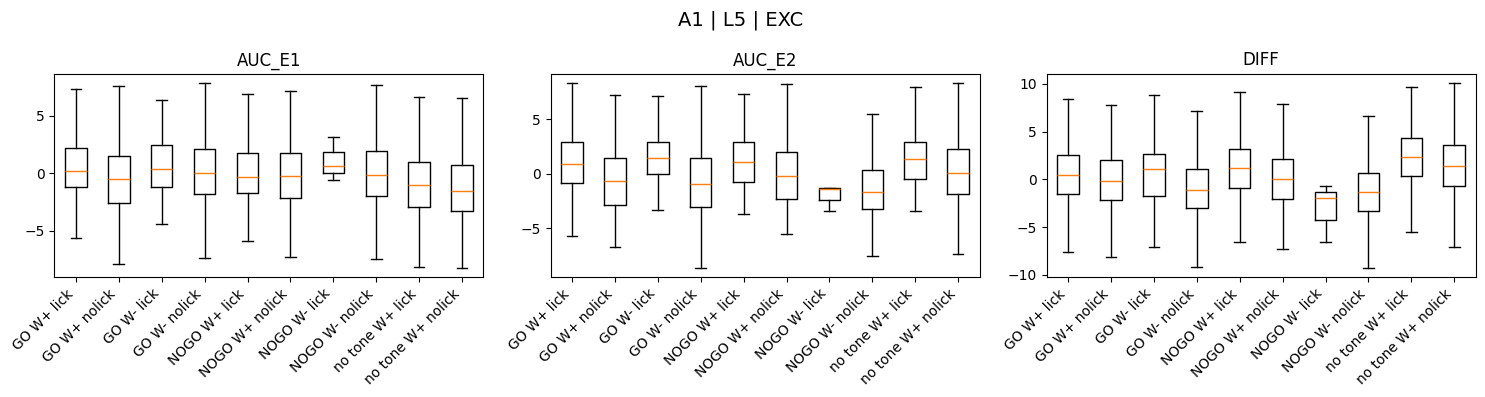

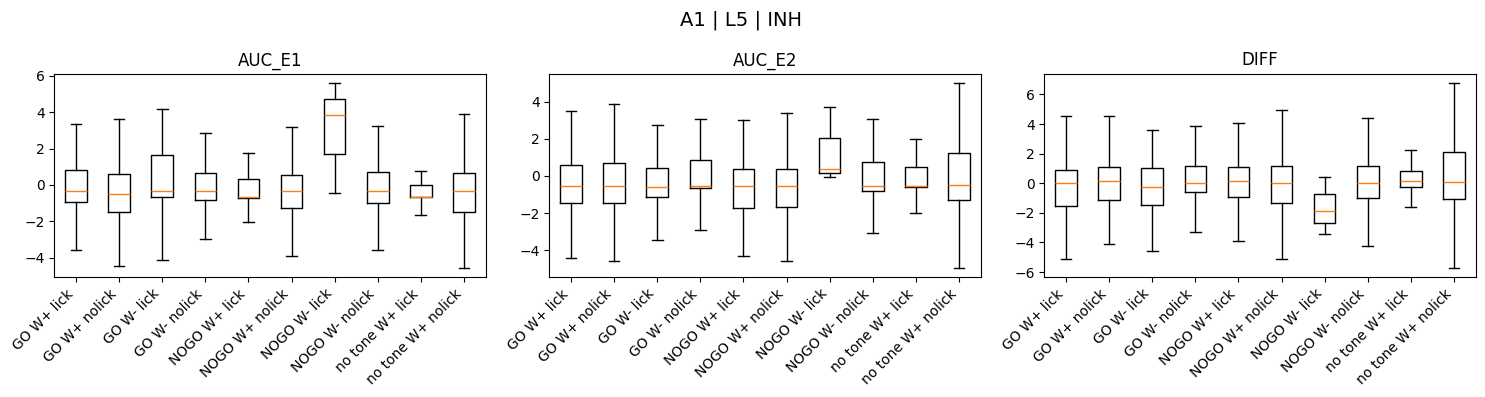

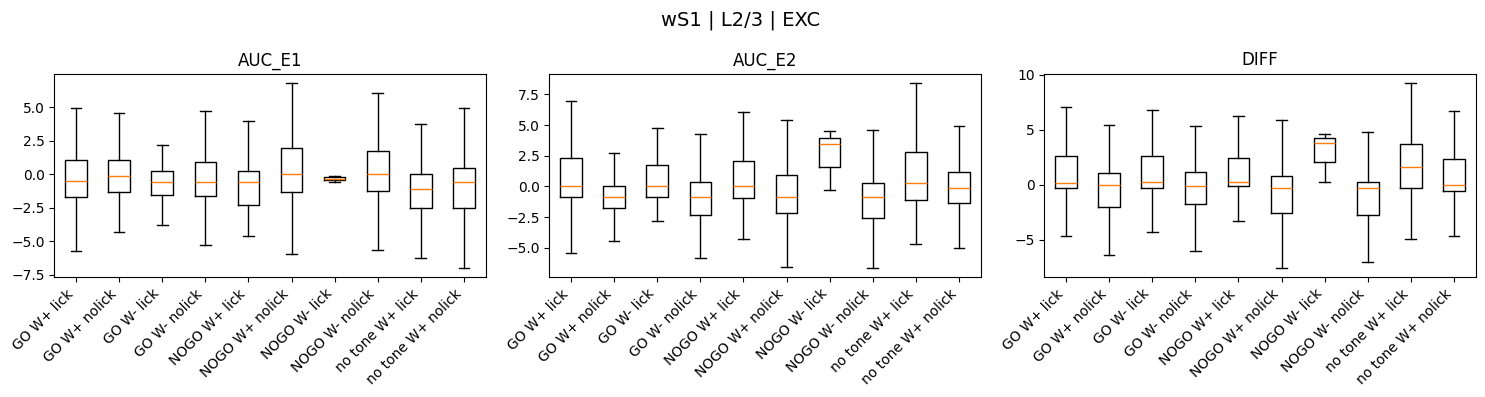

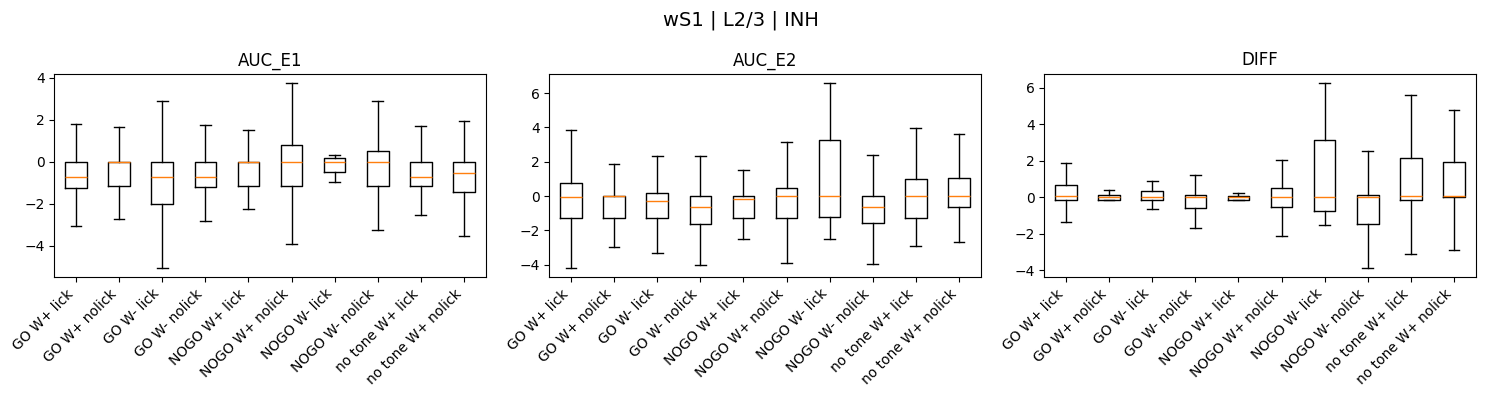

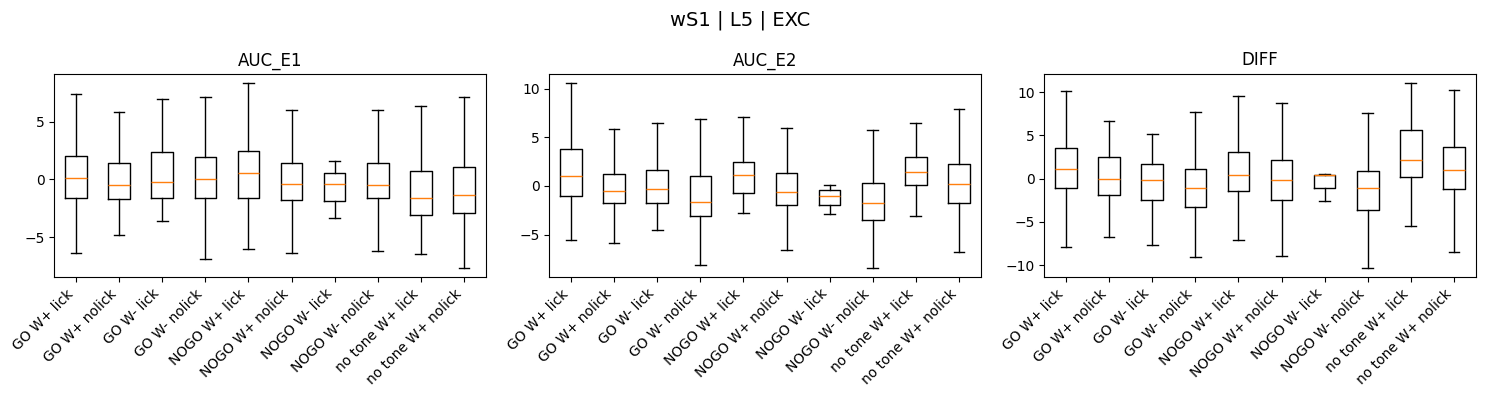

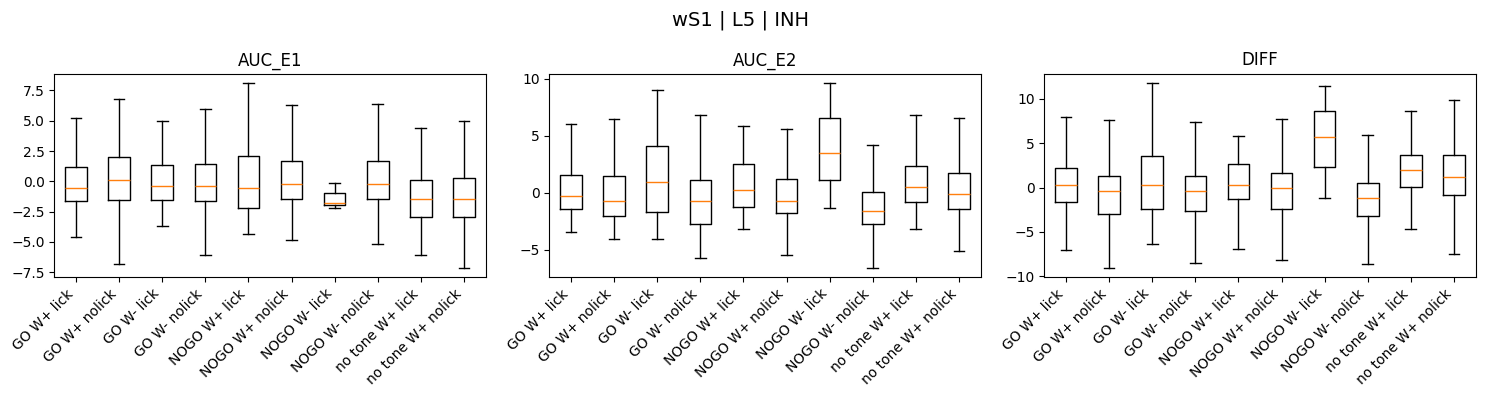

In [10]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =============================
# PARAMS
# =============================
E1 = range(8, 13)    # event 1 window
E2 = range(18, 23)   # event 2 window

# =============================
# LOAD + PREPROCESS (identique à ton pipeline)
# =============================
df = pd.read_csv("data/raw/train.csv")
meta = ["session_id", "trial_number", "TRIAL_TYPE"]

cand_cols = [c for c in df.columns if c not in meta]
df[cand_cols] = df[cand_cols].apply(pd.to_numeric, errors="coerce")

feature_cols = [c for c in cand_cols if pd.api.types.is_numeric_dtype(df[c])]

df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# =============================
# PARSE columns -> area / layer / type / time
# =============================
pat = re.compile(r"(.*)_time_(\d+)$")

rows = []
for c in feature_cols:
    m = pat.match(c)
    if not m:
        continue
    prefix, t = m.group(1), int(m.group(2))
    area, layer, typ = prefix.split("_")
    rows.append((c, area, layer, typ, t))

info = pd.DataFrame(rows, columns=["col", "area", "layer", "type", "time"])

# =============================
# COMPUTE AUC FEATURES PER GROUP
# =============================
group_cols = ["area", "layer", "type"]

feat_rows = []
for (area, layer, typ), sub in info.groupby(group_cols):
    e1_cols = sub[sub.time.isin(E1)].col.tolist()
    e2_cols = sub[sub.time.isin(E2)].col.tolist()
    if len(e1_cols) == 0 or len(e2_cols) == 0:
        continue

    auc1 = df[e1_cols].sum(axis=1)
    auc2 = df[e2_cols].sum(axis=1)
    diff = auc2 - auc1

    feat_rows.append(pd.DataFrame({
        "TRIAL_TYPE": df["TRIAL_TYPE"],
        "area": area,
        "layer": layer,
        "type": typ,
        "AUC_E1": auc1,
        "AUC_E2": auc2,
        "DIFF": diff
    }))

feat_df = pd.concat(feat_rows, ignore_index=True)
print("Computed feature rows:", feat_df.shape)

# =============================
# PLOT: choose some groups to inspect
# =============================
# Exemple : focus sur A1 et wS1
plot_groups = (
    feat_df
    .query("area in ['A1', 'wS1'] and layer in ['L2/3', 'L5']")
)

metrics = ["AUC_E1", "AUC_E2", "DIFF"]

for (area, layer, typ), sub in plot_groups.groupby(["area", "layer", "type"]):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
    fig.suptitle(f"{area} | {layer} | {typ}", fontsize=14)

    for ax, m in zip(axes, metrics):
        data = [
            sub[sub.TRIAL_TYPE == cls][m].values
            for cls in sorted(sub.TRIAL_TYPE.unique())
        ]
        ax.boxplot(data, showfliers=False)
        ax.set_title(m)
        ax.set_xticklabels(sorted(sub.TRIAL_TYPE.unique()), rotation=45, ha="right")

    plt.tight_layout()
    plt.show()


Event-based temporal feature augmentation with LOSO evaluation.
This pipeline evaluates a non-linear XGBoost classifier using leave-one-session-out cross-validation. Raw neural activity time-series are first z-score normalized per session and cleaned of constant features. Within each fold, missing values are imputed and the 400 most discriminative original features are selected using ANOVA. In parallel, event-locked temporal features are engineered for each brain region–layer–cell-type group by summarizing activity in predefined time windows around task events (AUC before and after the event, their difference, and ratio). These engineered features are concatenated with the selected original features and used to train the classifier. Performance is reported as mean LOSO accuracy across sessions.

In [11]:
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# =============================
# PARAMÈTRES
# =============================
K_TOP = 400
E1 = set(range(8, 13))      # 8..12
E2 = set(range(18, 23))     # 18..22
EPS = 1e-6

# =============================
# 1) Charger + nettoyage + features numériques
# =============================
df = pd.read_csv("data/raw/train.csv")
meta_cols = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop colonnes constantes
constant_cols = [
    c for c in df.columns
    if c not in meta_cols and df[c].nunique(dropna=False) <= 1
]
df = df.drop(columns=constant_cols)

# candidates = toutes sauf meta
cand_cols = [c for c in df.columns if c not in meta_cols]

# forcer numérique
df[cand_cols] = df[cand_cols].apply(pd.to_numeric, errors="coerce")

# garder numériques
feature_cols = [c for c in cand_cols if pd.api.types.is_numeric_dtype(df[c])]

# normalisation par session (comme toi)
df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# y / groups
le = LabelEncoder()
y = le.fit_transform(df["TRIAL_TYPE"].values)
num_classes = len(le.classes_)
groups = df["session_id"].values

print("Classes:", le.classes_)
print("Nb features (avant folds):", len(feature_cols))

# regex time / prefix
# ex: A1_L5_EXC_time_12  -> prefix=A1_L5_EXC, t=12
pat = re.compile(r"^(.*)_time_(\d+)$")

# prefixes globaux (pour avoir ~4*45 features stables sur tous les folds)
prefixes = []
for c in feature_cols:
    m = pat.match(c)
    if m:
        prefixes.append(m.group(1))
prefixes = sorted(set(prefixes))
P = len(prefixes)
print("Nb prefixes:", P, "=> engineered features:", 4 * P)

# =============================
# 2) Matrice complète
# =============================
X_all = df[feature_cols].to_numpy()
print("X_all shape:", X_all.shape)

# =============================
# 3) LOSO
# =============================
logo = LeaveOneGroupOut()
accs = []

for fold, (tr, te) in enumerate(logo.split(X_all, y, groups), 1):
    test_session = np.unique(groups[te])[0]

    X_train_raw = X_all[tr]
    X_test_raw  = X_all[te]
    y_train = y[tr]
    y_test  = y[te]

    # --- enlever colonnes all-NaN dans le TRAIN de ce fold
    mask_keep = ~np.all(np.isnan(X_train_raw), axis=0)

    X_train_raw = X_train_raw[:, mask_keep]
    X_test_raw  = X_test_raw[:, mask_keep]
    feature_cols_fold = [c for c, keep in zip(feature_cols, mask_keep) if keep]

    # =============================
    # A) Imputation
    # =============================
    imp = KNNImputer(n_neighbors=2)
    X_train = imp.fit_transform(X_train_raw)
    X_test  = imp.transform(X_test_raw)

    # =============================
    # B) ANOVA top 400 (sur features "brutes" du fold)
    # =============================
    f_scores, _ = f_classif(X_train, y_train)
    top = np.argsort(f_scores)[::-1][:min(K_TOP, X_train.shape[1])]
    X_train_top = X_train[:, top]
    X_test_top  = X_test[:, top]

    # =============================
    # C) ~180 features temporelles: 4 par prefix (AUC_E1, AUC_E2, diff, ratio)
    # =============================
    # mapping prefix -> indices de colonnes (dans l'espace du fold) pour E1/E2
    e1_idx_by_prefix = {p: [] for p in prefixes}
    e2_idx_by_prefix = {p: [] for p in prefixes}

    for j, c in enumerate(feature_cols_fold):
        m = pat.match(c)
        if not m:
            continue
        p = m.group(1)
        t = int(m.group(2))
        if p not in e1_idx_by_prefix:
            # prefix "nouveau" (rare) -> on l'ignore pour garder dimension stable
            continue
        if t in E1:
            e1_idx_by_prefix[p].append(j)
        if t in E2:
            e2_idx_by_prefix[p].append(j)

    # calc features (dimension stable: n_samples x (4*P))
    ntr = X_train.shape[0]
    nte = X_test.shape[0]
    X_train_eng = np.zeros((ntr, 4 * P), dtype=float)
    X_test_eng  = np.zeros((nte, 4 * P), dtype=float)

    for pi, p in enumerate(prefixes):
        e1_idx = e1_idx_by_prefix[p]
        e2_idx = e2_idx_by_prefix[p]

        # si une fenêtre est absente (après filtrage all-NaN), on laisse 0
        if len(e1_idx) > 0:
            auc1_tr = np.nansum(X_train[:, e1_idx], axis=1)
            auc1_te = np.nansum(X_test[:,  e1_idx], axis=1)
        else:
            auc1_tr = np.zeros(ntr)
            auc1_te = np.zeros(nte)

        if len(e2_idx) > 0:
            auc2_tr = np.nansum(X_train[:, e2_idx], axis=1)
            auc2_te = np.nansum(X_test[:,  e2_idx], axis=1)
        else:
            auc2_tr = np.zeros(ntr)
            auc2_te = np.zeros(nte)

        diff_tr  = auc2_tr - auc1_tr
        diff_te  = auc2_te - auc1_te
        ratio_tr = auc2_tr / (np.abs(auc1_tr) + EPS)
        ratio_te = auc2_te / (np.abs(auc1_te) + EPS)

        # écrire dans la matrice
        k0 = 4 * pi
        X_train_eng[:, k0 + 0] = auc1_tr
        X_train_eng[:, k0 + 1] = auc2_tr
        X_train_eng[:, k0 + 2] = diff_tr
        X_train_eng[:, k0 + 3] = ratio_tr

        X_test_eng[:, k0 + 0] = auc1_te
        X_test_eng[:, k0 + 1] = auc2_te
        X_test_eng[:, k0 + 2] = diff_te
        X_test_eng[:, k0 + 3] = ratio_te

    # sécurité NaN/inf
    X_train_eng = np.nan_to_num(X_train_eng, nan=0.0, posinf=0.0, neginf=0.0)
    X_test_eng  = np.nan_to_num(X_test_eng,  nan=0.0, posinf=0.0, neginf=0.0)

    # =============================
    # D) concat (top400 + ~180 engineered)
    # =============================
    X_train_final = np.hstack([X_train_top, X_train_eng])
    X_test_final  = np.hstack([X_test_top,  X_test_eng])

    # =============================
    # E) modèle best params
    # =============================
    model = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=0,
        n_jobs=-1,
        min_child_weight=5,
        gamma=0.1,
        reg_alpha=0.3,
        reg_lambda=1.0,
        verbosity=0
    )

    model.fit(X_train_final, y_train)
    y_pred = model.predict(X_test_final)
    acc = accuracy_score(y_test, y_pred)
    accs.append(acc)

    print(
        f"Fold {fold} — {test_session} — acc: {acc:.4f} | "
        f"kept_cols={X_train.shape[1]} | engineered={X_train_eng.shape[1]}"
    )

print("\n====================")
print("Mean LOSO accuracy:", float(np.mean(accs)))
print("Std  LOSO accuracy:", float(np.std(accs)))
print("====================")


Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']
Nb features (avant folds): 1350
Nb prefixes: 45 => engineered features: 180
X_all shape: (4407, 1350)
Fold 1 — PG082_20221113 — acc: 0.5619 | kept_cols=1350 | engineered=180
Fold 2 — PG082_20221114 — acc: 0.6221 | kept_cols=1350 | engineered=180
Fold 3 — PG083_20221125 — acc: 0.5833 | kept_cols=1350 | engineered=180
Fold 4 — PG083_20221129 — acc: 0.5497 | kept_cols=1350 | engineered=180
Fold 5 — PG084_20221206 — acc: 0.5689 | kept_cols=1350 | engineered=180
Fold 6 — PG084_20221207 — acc: 0.5691 | kept_cols=1350 | engineered=180
Fold 7 — PG085_20221213 — acc: 0.4522 | kept_cols=1350 | engineered=180
Fold 8 — PG085_20221214 — acc: 0.5845 | kept_cols=1320 | engineered=180

Mean LOSO accuracy: 0.5614777657434427
Std  LOSO accuracy: 0.04595478622623872


the outcome is worst than without feature engineering 
Hypothsis
Most of the information that generalizes across animals is contained in a limited subset of instantaneous neural activity features around task events. Explicit temporal summarization does not improve performance, suggesting that temporal structure is either already implicitly captured or not consistent across subjects.

Below we try to select the 400 better features among the brutes features and the 180 engineered ones.

In [ ]:
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# =============================
# PARAMÈTRES
# =============================
K_FINAL = 500
E1 = set(range(8, 13))      # 8..12
E2 = set(range(18, 23))     # 18..22
EPS = 1e-6

# =============================
# 1) Chargement + nettoyage
# =============================
df = pd.read_csv("data/raw/train.csv")
meta_cols = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop colonnes constantes
constant_cols = [
    c for c in df.columns
    if c not in meta_cols and df[c].nunique(dropna=False) <= 1
]
df = df.drop(columns=constant_cols)

# features numériques
cand_cols = [c for c in df.columns if c not in meta_cols]
df[cand_cols] = df[cand_cols].apply(pd.to_numeric, errors="coerce")
feature_cols = [c for c in cand_cols if pd.api.types.is_numeric_dtype(df[c])]

# normalisation par session
df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# labels / groups
le = LabelEncoder()
y = le.fit_transform(df["TRIAL_TYPE"].values)
groups = df["session_id"].values
num_classes = len(le.classes_)

print("Classes:", le.classes_)
print("Nb features brutes:", len(feature_cols))

# regex time
pat = re.compile(r"^(.*)_time_(\d+)$")

# prefixes globaux (stables inter-folds)
prefixes = sorted({
    pat.match(c).group(1)
    for c in feature_cols if pat.match(c)
})
P = len(prefixes)
print(f"Nb prefixes: {P}  -> engineered features: {4 * P}")

# =============================
# 2) Matrice brute
# =============================
X_all = df[feature_cols].to_numpy()

# =============================
# 3) LOSO
# =============================
logo = LeaveOneGroupOut()
accs = []

for fold, (tr, te) in enumerate(logo.split(X_all, y, groups), 1):
    test_session = np.unique(groups[te])[0]

    X_train_raw = X_all[tr]
    X_test_raw  = X_all[te]
    y_train = y[tr]
    y_test  = y[te]

    # --- retirer colonnes all-NaN dans le TRAIN
    mask_keep = ~np.all(np.isnan(X_train_raw), axis=0)
    X_train_raw = X_train_raw[:, mask_keep]
    X_test_raw  = X_test_raw[:, mask_keep]
    feature_cols_fold = [c for c, k in zip(feature_cols, mask_keep) if k]

    # =============================
    # A) Imputation
    # =============================
    imp = KNNImputer(n_neighbors=2)
    X_train = imp.fit_transform(X_train_raw)
    X_test  = imp.transform(X_test_raw)

    # =============================
    # B) Features engineered (4 × prefix)
    # =============================
    e1_idx = {p: [] for p in prefixes}
    e2_idx = {p: [] for p in prefixes}

    for j, c in enumerate(feature_cols_fold):
        m = pat.match(c)
        if not m:
            continue
        p, t = m.group(1), int(m.group(2))
        if p in e1_idx:
            if t in E1: e1_idx[p].append(j)
            if t in E2: e2_idx[p].append(j)

    def build_eng(X):
        out = np.zeros((X.shape[0], 4 * P))
        for i, p in enumerate(prefixes):
            a1 = np.nansum(X[:, e1_idx[p]], axis=1) if e1_idx[p] else 0
            a2 = np.nansum(X[:, e2_idx[p]], axis=1) if e2_idx[p] else 0
            out[:, 4*i+0] = a1
            out[:, 4*i+1] = a2
            out[:, 4*i+2] = a2 - a1
            out[:, 4*i+3] = a2 / (np.abs(a1) + EPS)
        return np.nan_to_num(out)

    X_train_eng = build_eng(X_train)
    X_test_eng  = build_eng(X_test)

    # =============================
    # C) CONCAT brutes + engineered
    # =============================
    X_train_all = np.hstack([X_train, X_train_eng])
    X_test_all  = np.hstack([X_test,  X_test_eng])

    # =============================
    # D) ANOVA SUR TOUT → TOP 400
    # =============================
    f_scores, _ = f_classif(X_train_all, y_train)
    top = np.argsort(f_scores)[::-1][:min(K_FINAL, X_train_all.shape[1])]

    X_train_final = X_train_all[:, top]
    X_test_final  = X_test_all[:,  top]

    # =============================
    # E) Modèle
    # =============================
    model = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=0,
        n_jobs=-1,
        min_child_weight=5,
        gamma=0.1,
        reg_alpha=0.3,
        reg_lambda=1.0,
        verbosity=0
    )

    model.fit(X_train_final, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_final))
    accs.append(acc)

    print(
        f"Fold {fold} — {test_session} — acc={acc:.4f} | "
        f"final_dim={X_train_final.shape[1]}"
    )

print("\n====================")
print("Mean LOSO accuracy:", float(np.mean(accs)))
print("Std  LOSO accuracy:", float(np.std(accs)))
print("====================")

# K = 400:
# Fold 1 — PG082_20221113 — acc=0.5453 | final_dim=400
# Fold 2 — PG082_20221114 — acc=0.6156 | final_dim=400
# Fold 3 — PG083_20221125 — acc=0.5912 | final_dim=400
# Fold 4 — PG083_20221129 — acc=0.5364 | final_dim=400
# Fold 5 — PG084_20221206 — acc=0.5866 | final_dim=400
# Fold 6 — PG084_20221207 — acc=0.5691 | final_dim=400
# Fold 7 — PG085_20221213 — acc=0.4428 | final_dim=400
# Fold 8 — PG085_20221214 — acc=0.5791 | final_dim=400

# ====================
# Mean LOSO accuracy: 0.5582809681019583
# Std  LOSO accuracy: 0.04964335538136614
# ====================

# K = 500
# Fold 1 — PG082_20221113 — acc=0.5695 | final_dim=500
# Fold 2 — PG082_20221114 — acc=0.6254 | final_dim=500
# Fold 3 — PG083_20221125 — acc=0.5849 | final_dim=500
# Fold 4 — PG083_20221129 — acc=0.5364 | final_dim=500
# Fold 5 — PG084_20221206 — acc=0.5571 | final_dim=500
# Fold 6 — PG084_20221207 — acc=0.5758 | final_dim=500
# Fold 7 — PG085_20221213 — acc=0.4578 | final_dim=500
# Fold 8 — PG085_20221214 — acc=0.5701 | final_dim=500

# ====================
# Mean LOSO accuracy: 0.5596296950153773
# Std  LOSO accuracy: 0.04521028152497131
# ====================



Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']
Nb features brutes: 1350
Nb prefixes: 45  -> engineered features: 180
Fold 1 — PG082_20221113 — acc=0.5695 | final_dim=500
Fold 2 — PG082_20221114 — acc=0.6254 | final_dim=500
Fold 3 — PG083_20221125 — acc=0.5849 | final_dim=500
Fold 4 — PG083_20221129 — acc=0.5364 | final_dim=500
Fold 5 — PG084_20221206 — acc=0.5571 | final_dim=500
Fold 6 — PG084_20221207 — acc=0.5758 | final_dim=500
Fold 7 — PG085_20221213 — acc=0.4578 | final_dim=500


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [1356 1357 1358 1359] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


Fold 8 — PG085_20221214 — acc=0.5701 | final_dim=500

Mean LOSO accuracy: 0.5596296950153773
Std  LOSO accuracy: 0.04521028152497131


Once again results are the same, even worst. I try to use the log reg on the 400 best among raw and engineerd features. 

In [14]:
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression

# =============================
# PARAMÈTRES
# =============================
BEST_N = 2
BEST_C = 0.03
K_FINAL = 400

E1 = set(range(8, 13))      # 8..12
E2 = set(range(18, 23))     # 18..22
EPS = 1e-6

TRAIN_PATH = "data/raw/train.csv"
TEST_PATH  = "data/raw/test.csv"
SAMPLE_SUB = "data/raw/sample_submission.csv"
OUT_PATH   = "data/submission_logreg_l1_top400_rawpluseng.csv"

# =============================
# OUTILS
# =============================
pat = re.compile(r"^(.*)_time_(\d+)$")

def zscore_per_session(df, feature_cols):
    df = df.copy()
    df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
        lambda x: (x - x.mean()) / (x.std() + 1e-8)
    )
    return df

def get_prefixes(feature_cols):
    prefs = []
    for c in feature_cols:
        m = pat.match(c)
        if m:
            prefs.append(m.group(1))
    return sorted(set(prefs))

def build_eng_features(X, feature_cols_fold, prefixes, E1, E2, eps=1e-6):
    """
    X: numpy (n_samples, p_fold) déjà imputé
    feature_cols_fold: list[str] longueur p_fold
    prefixes: list[str] stable global
    retourne (n_samples, 4*P)
    """
    P = len(prefixes)
    e1_idx = {p: [] for p in prefixes}
    e2_idx = {p: [] for p in prefixes}

    for j, c in enumerate(feature_cols_fold):
        m = pat.match(c)
        if not m:
            continue
        p, t = m.group(1), int(m.group(2))
        if p not in e1_idx:
            continue
        if t in E1:
            e1_idx[p].append(j)
        if t in E2:
            e2_idx[p].append(j)

    out = np.zeros((X.shape[0], 4 * P), dtype=float)

    for i, p in enumerate(prefixes):
        if e1_idx[p]:
            a1 = np.nansum(X[:, e1_idx[p]], axis=1)
        else:
            a1 = 0.0
        if e2_idx[p]:
            a2 = np.nansum(X[:, e2_idx[p]], axis=1)
        else:
            a2 = 0.0

        diff = a2 - a1
        ratio = a2 / (np.abs(a1) + eps)

        k0 = 4 * i
        out[:, k0 + 0] = a1
        out[:, k0 + 1] = a2
        out[:, k0 + 2] = diff
        out[:, k0 + 3] = ratio

    return np.nan_to_num(out, nan=0.0, posinf=0.0, neginf=0.0)

# =============================
# 1) CHARGER TRAIN + NETTOYAGE
# =============================
df_train = pd.read_csv(TRAIN_PATH)
meta_cols = ["session_id", "trial_number", "TRIAL_TYPE"]

constant_cols = [
    c for c in df_train.columns
    if c not in meta_cols and df_train[c].nunique(dropna=False) <= 1
]
df_train = df_train.drop(columns=constant_cols)

cand_cols = [c for c in df_train.columns if c not in meta_cols]
df_train[cand_cols] = df_train[cand_cols].apply(pd.to_numeric, errors="coerce")
feature_cols = [c for c in cand_cols if pd.api.types.is_numeric_dtype(df_train[c])]

df_train = zscore_per_session(df_train, feature_cols)

le = LabelEncoder()
y = le.fit_transform(df_train["TRIAL_TYPE"].values)
groups = df_train["session_id"].values

X_all = df_train[feature_cols].to_numpy()
prefixes = get_prefixes(feature_cols)

print("Classes:", le.classes_)
print("Nb features brutes:", len(feature_cols))
print("Nb prefixes:", len(prefixes), "=> engineered:", 4 * len(prefixes))
print("X_all shape:", X_all.shape)

# =============================
# 2) LOSO EVAL (OPTIONNEL MAIS UTILE)
# =============================
logo = LeaveOneGroupOut()
accs = []

for fold, (tr, te) in enumerate(logo.split(X_all, y, groups), 1):
    test_session = np.unique(groups[te])[0]

    Xtr_raw = X_all[tr]
    Xte_raw = X_all[te]
    ytr = y[tr]
    yte = y[te]

    # enlever colonnes all-NaN dans train fold
    mask_keep = ~np.all(np.isnan(Xtr_raw), axis=0)
    Xtr_raw = Xtr_raw[:, mask_keep]
    Xte_raw = Xte_raw[:, mask_keep]
    fcols_fold = [c for c, k in zip(feature_cols, mask_keep) if k]

    # imputation
    imp = KNNImputer(n_neighbors=BEST_N)
    Xtr = imp.fit_transform(Xtr_raw)
    Xte = imp.transform(Xte_raw)

    # engineered
    Xtr_eng = build_eng_features(Xtr, fcols_fold, prefixes, E1, E2, EPS)
    Xte_eng = build_eng_features(Xte, fcols_fold, prefixes, E1, E2, EPS)

    # concat brutes + engineered
    Xtr_allfeat = np.hstack([Xtr, Xtr_eng])
    Xte_allfeat = np.hstack([Xte, Xte_eng])

    # ANOVA sur TOUT -> top 400
    f_scores, _ = f_classif(Xtr_allfeat, ytr)
    top = np.argsort(f_scores)[::-1][:min(K_FINAL, Xtr_allfeat.shape[1])]

    Xtr_final = Xtr_allfeat[:, top]
    Xte_final = Xte_allfeat[:, top]

    # LogReg L1
    clf = LogisticRegression(
        penalty="l1",
        C=BEST_C,
        solver="liblinear",
        max_iter=2000
    )
    clf.fit(Xtr_final, ytr)
    pred = clf.predict(Xte_final)

    acc = accuracy_score(yte, pred)
    accs.append(acc)

    print(f"Fold {fold} — {test_session} — acc={acc:.4f} | final_dim={Xtr_final.shape[1]}")

print("\n====================")
print("Mean LOSO accuracy:", float(np.mean(accs)))
print("Std  LOSO accuracy:", float(np.std(accs)))
print("====================\n")

# =============================
# 3) FIT SUR TOUT LE TRAIN + SUBMISSION
# =============================
# all-NaN cols sur train complet
mask_keep_full = ~np.all(np.isnan(X_all), axis=0)
X_train_raw_full = X_all[:, mask_keep_full]
feature_cols_full = [c for c, k in zip(feature_cols, mask_keep_full) if k]

# imputer train complet
imp_full = KNNImputer(n_neighbors=BEST_N)
X_train_full = imp_full.fit_transform(X_train_raw_full)

# engineered sur train complet
X_train_eng_full = build_eng_features(X_train_full, feature_cols_full, prefixes, E1, E2, EPS)

# concat + ANOVA top400 (sur tout le train)
X_train_allfeat_full = np.hstack([X_train_full, X_train_eng_full])
f_scores_full, _ = f_classif(X_train_allfeat_full, y)
top_full = np.argsort(f_scores_full)[::-1][:min(K_FINAL, X_train_allfeat_full.shape[1])]

X_train_final_full = X_train_allfeat_full[:, top_full]

# fit logreg final
clf_full = LogisticRegression(
    penalty="l1",
    C=BEST_C,
    solver="liblinear",
    max_iter=2000
)
clf_full.fit(X_train_final_full, y)

# =============================
# TEST : preprocess identique
# =============================
df_test = pd.read_csv(TEST_PATH)

# drop mêmes constantes (si présentes)
df_test = df_test.drop(columns=[c for c in constant_cols if c in df_test.columns])

# numeric + align cols
cand_test = [c for c in df_test.columns if c not in ["session_id", "trial_number"]]
df_test[cand_test] = df_test[cand_test].apply(pd.to_numeric, errors="coerce")

# zscore par session (test)
feat_test = [c for c in df_test.columns if c not in ["session_id", "trial_number"]]
df_test = zscore_per_session(df_test, feat_test)

# reindex exactement sur les feature_cols brutes du train
X_test_all = df_test.reindex(columns=feature_cols).to_numpy()

# appliquer le même mask_keep_full (colonnes gardées sur train complet)
X_test_raw_full = X_test_all[:, mask_keep_full]

# impute avec imp_full
X_test_full = imp_full.transform(X_test_raw_full)

# engineered test
X_test_eng_full = build_eng_features(X_test_full, feature_cols_full, prefixes, E1, E2, EPS)

# concat + sélectionner top_full
X_test_allfeat_full = np.hstack([X_test_full, X_test_eng_full])
X_test_final_full = X_test_allfeat_full[:, top_full]

# prédiction
y_pred_test = le.inverse_transform(clf_full.predict(X_test_final_full))

sub = pd.read_csv(SAMPLE_SUB)
sub["TRIAL_TYPE"] = y_pred_test
sub.to_csv(OUT_PATH, index=False)

print(f"Submission écrite: {OUT_PATH}")
print("Train final dim:", X_train_final_full.shape, "Test final dim:", X_test_final_full.shape)


Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']
Nb features brutes: 1350
Nb prefixes: 45 => engineered: 180
X_all shape: (4407, 1350)


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fold 1 — PG082_20221113 — acc=0.5091 | final_dim=400


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fold 2 — PG082_20221114 — acc=0.5081 | final_dim=400


...

Fold 7 — PG085_20221213 — acc=0.3902 | final_dim=400


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [1356 1357 1358 1359] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fold 8 — PG085_20221214 — acc=0.4964 | final_dim=400

Mean LOSO accuracy: 0.494283695722284
Std  LOSO accuracy: 0.04372770730609451



/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Submission écrite: data/submission_logreg_l1_top400_rawpluseng.csv
Train final dim: (4407, 400) Test final dim: (2292, 400)


Plotting the normalized activity per neurone area, layer and type.